# 02 · Embudo de captación y cohortes de compradores

**Sesión 2 · Inteligencia de mercado** (ruta Paid Media, semana 1: embudo por cohorte con datos públicos).

Preguntas:
1. ¿Cuánto vale un lead de cada canal, no solo cuánto convierte? Valor = P(cierre) × GMV esperado del contrato en sus primeros 90 días.
2. ¿Los compradores vuelven? ¿Cambia por cohorte?
3. ¿Qué pasó mes a mes con pedidos, ticket, entregas y reseñas?

Solo usa `data/processed/` (publicado en el repo): `python -m growth_lab.embudo` regenera las tablas.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from growth_lab import db, embudo

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
con = db.conectar(db.PROCESSED)
canal = embudo.embudo_canal(con)
canal.round(3)

,canal,leads,cerrados,cerrados_maduros,maduros_que_venden,gmv_maduros,tasa_cierre,tasa_venta_si_cierra,gmv_por_contrato,gmv_por_lead,gmv_por_lead_p05,gmv_por_lead_p95,ingreso_por_lead,ingreso_por_lead_p05,ingreso_por_lead_p95,comision,ventana_dias
0,organic_search,2296,271,206,81,90557.06,0.118,0.393,439.597,51.886,28.123,84.182,7.783,4.218,12.627,0.15,90
1,paid_search,1586,195,145,79,74492.46,0.123,0.545,513.741,63.165,40.442,91.185,9.475,6.066,13.678,0.15,90
2,social,1350,75,55,24,12767.02,0.056,0.436,232.128,12.896,6.395,20.932,1.934,0.959,3.140,0.15,90
3,unknown,1099,179,153,63,128858.79,0.163,0.412,842.214,137.176,41.086,297.178,20.576,6.163,44.577,0.15,90
4,direct_traffic,499,56,49,22,8980.43,0.112,0.449,183.274,20.568,11.472,30.391,3.085,1.721,4.559,0.15,90
5,email,493,15,13,5,6129.69,0.030,0.385,471.515,14.346,0.367,39.834,2.152,0.055,5.975,0.15,90
6,referral,284,24,18,8,11480.76,0.085,0.444,637.820,53.900,11.443,111.206,8.085,1.716,16.681,0.15,90
7,other,150,4,4,1,5283.98,0.027,0.250,1320.995,35.227,0.000,105.680,5.284,0.000,15.852,0.15,90
8,display,118,6,6,1,273.00,0.051,0.167,45.500,2.314,0.000,6.941,0.347,0.000,1.041,0.15,90
9,other_publicities,65,3,3,0,0.00,0.046,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.15,90


## 1. Valor de un lead por canal (IC 90% por bootstrap)

Se muestran los canales con al menos 10 contratos maduros; con menos, el intervalo no dice nada.

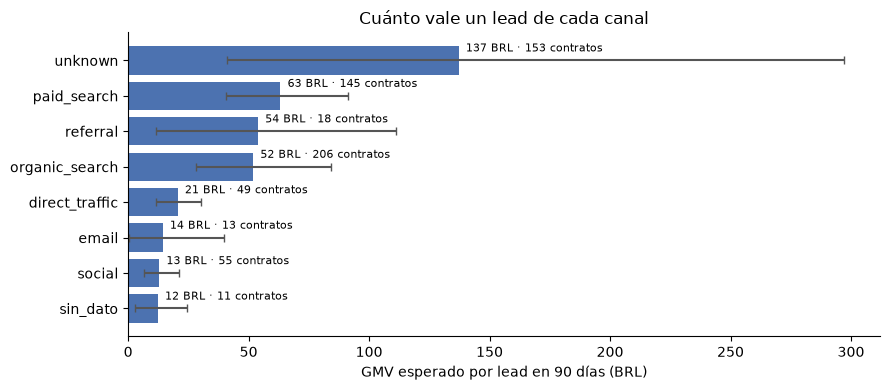

In [2]:
v = canal[canal.cerrados_maduros >= 10].sort_values("gmv_por_lead")
fig, ax = plt.subplots()
err = [v.gmv_por_lead - v.gmv_por_lead_p05, v.gmv_por_lead_p95 - v.gmv_por_lead]
ax.barh(v.canal, v.gmv_por_lead, xerr=err, color="#4C72B0", ecolor="#555", capsize=3)
for y, (val, n) in enumerate(zip(v.gmv_por_lead, v.cerrados_maduros)):
    ax.text(val + 3, y + 0.25, f"{val:,.0f} BRL · {n} contratos", fontsize=8)
ax.set_xlabel("GMV esperado por lead en 90 días (BRL)")
ax.set_title("Cuánto vale un lead de cada canal")
fig.tight_layout(); fig.savefig("../docs/img/embudo_valor_por_lead.png", dpi=150); plt.show()

### Descomposición: ¿el canal gana porque cierra más o porque sus vendedores venden más?

In [3]:
canal[canal.cerrados_maduros >= 10][["canal", "leads", "tasa_cierre", "tasa_venta_si_cierra", "gmv_por_contrato", "gmv_por_lead"]].round(3)

,canal,leads,tasa_cierre,tasa_venta_si_cierra,gmv_por_contrato,gmv_por_lead
0,organic_search,2296,0.118,0.393,439.597,51.886
1,paid_search,1586,0.123,0.545,513.741,63.165
2,social,1350,0.056,0.436,232.128,12.896
3,unknown,1099,0.163,0.412,842.214,137.176
4,direct_traffic,499,0.112,0.449,183.274,20.568
5,email,493,0.030,0.385,471.515,14.346
6,referral,284,0.085,0.444,637.820,53.900
10,sin_dato,60,0.233,0.273,52.818,12.324


## 2. Sensibilidad a la ventana (decisión 002)

Ventana más larga = más valor por contrato, pero menos contratos maduros (más ruido).

In [4]:
sens = pd.concat([embudo.embudo_canal(con, d, n_boot=300).assign(ventana=d) for d in (60, 90, 120, 180)])
principales = ["paid_search", "organic_search", "referral", "social", "direct_traffic", "email"]
tabla = sens[sens.canal.isin(principales)].pivot(index="canal", columns="ventana", values="gmv_por_lead").round(1)
tabla["maduros_90d"] = canal.set_index("canal").cerrados_maduros
tabla.loc[principales]

ventana,60,90,120,180,maduros_90d
canal,,,,,
paid_search,38.7,63.2,93.1,81.9,145
organic_search,37.3,51.9,85.7,132.0,206
referral,32.3,53.9,42.1,104.0,18
social,7.2,12.9,31.1,52.0,55
direct_traffic,10.9,20.6,29.6,59.2,49
email,3.9,14.3,20.3,27.4,13


In [5]:
sens[sens.canal.isin(principales)].pivot(index="canal", columns="ventana", values="cerrados_maduros").loc[principales]

ventana,60,90,120,180
canal,,,,
paid_search,161,145,119,39
organic_search,227,206,175,67
referral,19,18,11,4
social,63,55,46,15
direct_traffic,53,49,41,18
email,13,13,10,1


## 3. Cohortes de compradores: recompra acumulada

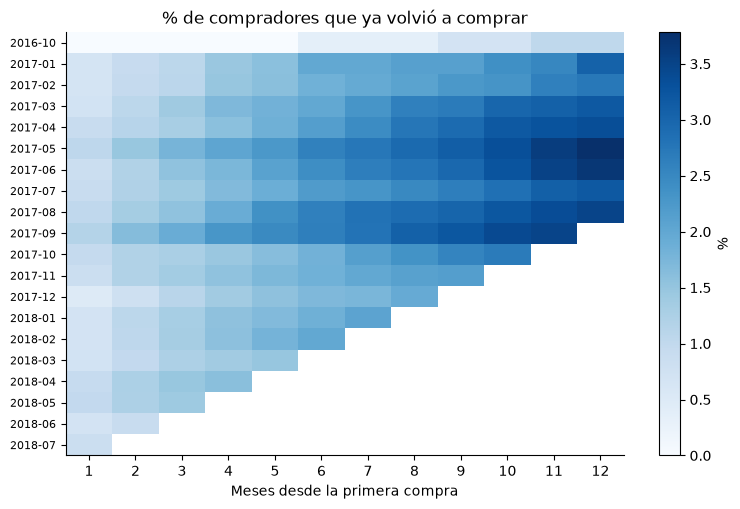

mes,1,3,6,12
count,20.00,18.00,15.00,9.00
mean,0.79,1.31,2.00,3.06
std,0.25,0.39,0.55,0.82
min,0.00,0.00,0.34,1.03
25%,0.69,1.25,1.84,3.06
50%,0.84,1.34,1.98,3.19
75%,0.94,1.46,2.31,3.49
max,1.15,1.91,2.63,3.78


In [6]:
coh = embudo.cohortes_compradores(con)
mapa = coh.pivot(index="cohorte", columns="mes", values="pct_recompra_acum") * 100
fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(mapa, aspect="auto", cmap="Blues")
ax.set_yticks(range(len(mapa)), [pd.Timestamp(c).strftime("%Y-%m") for c in mapa.index], fontsize=8)
ax.set_xticks(range(len(mapa.columns)), mapa.columns)
ax.set_xlabel("Meses desde la primera compra"); ax.set_title("% de compradores que ya volvió a comprar")
fig.colorbar(im, ax=ax, label="%"); plt.show()
mapa[[1, 3, 6, 12]].describe().round(2)

## 4. KPIs mensuales

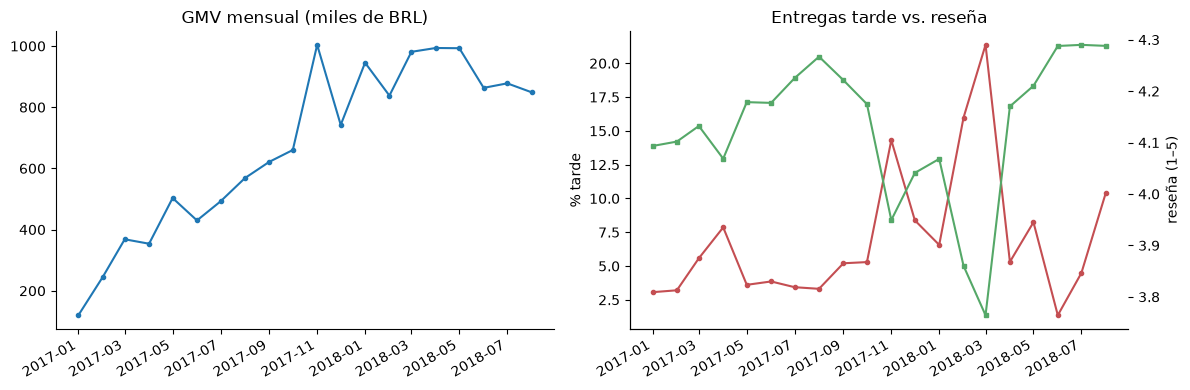

Correlación mensual % tarde vs. reseña: -0.81


,mes,pedidos,gmv,aov,pct_nuevos,pct_entrega_tarde,resena_media
3,2017-01-01,787,120098.27,152.603,0.999,0.031,4.093
4,2017-02-01,1718,244959.35,142.584,0.998,0.032,4.102
5,2017-03-01,2617,368341.32,140.749,0.998,0.056,4.132
6,2017-04-01,2377,353842.98,148.861,0.991,0.079,4.069
7,2017-05-01,3640,503159.19,138.231,0.992,0.036,4.179
8,2017-06-01,3205,429916.61,134.139,0.987,0.039,4.177
9,2017-07-01,3946,492287.30,124.756,0.987,0.034,4.225
10,2017-08-01,4272,568245.79,133.016,0.985,0.033,4.267
11,2017-09-01,4227,621415.91,147.011,0.981,0.052,4.221
12,2017-10-01,4547,660179.62,145.190,0.980,0.053,4.175


In [7]:
k = embudo.kpis_mensuales(con)
k = k[(k.mes >= pd.Timestamp("2017-01-01")) & (k.mes <= pd.Timestamp("2018-08-01"))]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(k.mes, k.gmv / 1e3, marker="o", ms=3); a1.set_title("GMV mensual (miles de BRL)")
a2.plot(k.mes, k.pct_entrega_tarde * 100, marker="o", ms=3, color="#C44E52", label="% entregas tarde")
a2b = a2.twinx(); a2b.plot(k.mes, k.resena_media, marker="s", ms=3, color="#55A868", label="reseña media")
a2.set_title("Entregas tarde vs. reseña"); a2.set_ylabel("% tarde"); a2b.set_ylabel("reseña (1–5)")
fig.autofmt_xdate(); fig.tight_layout(); plt.show()
print("Correlación mensual % tarde vs. reseña:", round(k.pct_entrega_tarde.corr(k.resena_media), 2))
k[["mes", "pedidos", "gmv", "aov", "pct_nuevos", "pct_entrega_tarde", "resena_media"]].round(3)

## Mis conclusiones (Neider)

1. **Priorizo búsqueda (pagada + orgánica).** Un lead de búsqueda pagada vale 63 BRL y uno de orgánica 52; están empatados estadísticamente y valen de 4 a 5 veces más que uno de social (13). Social y display quedan en revisión. No elijo entre pagada y orgánica hasta tener costos (sesión 4).
2. **La pagada gana por lo que pasa después del cierre, no por cerrar más:** cierra casi igual (12,3% vs. 11,8%), pero el 55% de sus contratos vende en 90 días frente al 39% de la orgánica.
3. **Ventana de 90 días** (decisión 002): a 180 días el orden cambia, pero con muy pocos contratos para creerle.
4. **El comprador de Olist no recompra:** 3% al año y estable entre cohortes. El CLV no tiene señal aquí; lo hago con Complete Journey.
5. **Entregas tarde y reseña van juntas** (correlación mensual −0,81), pero es correlación: los meses malos coinciden con Black Friday y picos de demanda. Lo dejo como hipótesis para la sesión de causalidad.